# Visualizing Spiking Data

`braintools.visualize` has plotting functions for the standard views of spiking data. This notebook builds a small simulated data set and walks through them:

| View | Function | Input |
|---|---|---|
| raster | `spike_raster` | spike times (list of trains, or times + neuron ids) |
| raster from a simulation | `raster_plot` | boolean spike matrix `(time, neuron)` |
| traces | `line_plot` | value matrix `(time, neuron)` |
| population rate / PSTH | `population_activity`, `spike_histogram` | rate matrix, or spike times |
| inter-spike intervals | `isi_distribution` | spike times |
| spatial rate map | `firing_rate_map` | rates + positions, or a 2-D map |

All functions draw into an existing `ax` when one is passed (and return it), so they compose into multi-panel figures.

## 1. Setup and Data

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import braintools

plt.rcParams["figure.dpi"] = 90
rng = np.random.default_rng(0)

A population of 60 neurons in three groups with different firing statistics, recorded in 20 trials of 2 s. A stimulus at $t = 0.5$ s raises the rate of the first 30 neurons for about 200 ms. Spike times are in seconds.

- **Poisson** neurons (0–29): inhomogeneous Poisson process, 5 Hz baseline, up to 40 Hz after the stimulus;
- **regular** neurons (30–44): gamma-distributed intervals of order 8 at 10 Hz;
- **bursty** neurons (45–59): bursts of 3–5 spikes 4 ms apart, at 2 bursts per second.

In [2]:
T, n_trials, dt = 2.0, 20, 0.001
t_grid = np.arange(0, T, dt)

def poisson_rate(t):
    # 5 Hz baseline, 35 Hz response decaying with 100 ms after the stimulus at 0.5 s
    return 5.0 + 35.0 * (t >= 0.5) * np.exp(-(t - 0.5) / 0.1)

def poisson_train(rate):
    return t_grid[rng.random(t_grid.size) < rate * dt]

def regular_train(rate=10.0, k=8):
    isis = rng.gamma(k, 1.0 / (k * rate), size=int(3 * rate * T))
    t = np.cumsum(isis) - rng.uniform(0, 1.0 / rate)
    return t[(t >= 0) & (t < T)]

def bursty_train(burst_rate=2.0):
    starts = np.sort(rng.uniform(0, T, rng.poisson(burst_rate * T)))
    t = np.concatenate([s + 0.004 * np.arange(rng.integers(3, 6)) for s in starts]) if len(starts) else np.zeros(0)
    return np.sort(t[t < T])

def one_trial():
    return ([poisson_train(poisson_rate(t_grid)) for _ in range(30)]
            + [regular_train() for _ in range(15)]
            + [bursty_train() for _ in range(15)])

trials = [one_trial() for _ in range(n_trials)]
spikes = trials[0]                       # a single trial: list of 60 arrays of spike times
print("neurons:", len(spikes), " spikes in trial 0:", sum(len(s) for s in spikes))

neurons: 60  spikes in trial 0: 986


## 2. Raster Plots

`spike_raster` takes either a list of spike-time arrays (one per neuron, as here) or a flat array of times with a matching `neuron_ids` array. `time_range` and `neuron_range` select a window; `color` may be one color or one color per spike.

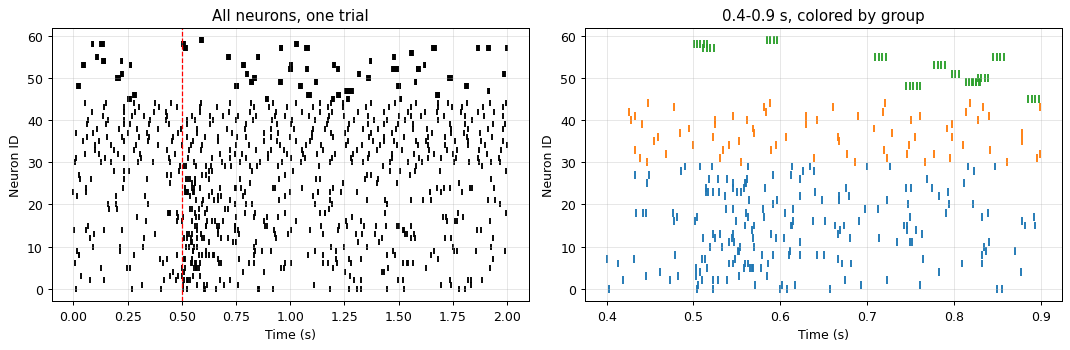

In [3]:
groups = np.repeat([0, 1, 2], [30, 15, 15])
colors = np.array(["C0", "C1", "C2"])
times = np.concatenate(spikes)
ids = np.concatenate([np.full(len(s), i) for i, s in enumerate(spikes)])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
braintools.visualize.spike_raster(spikes, ax=ax[0], markersize=20, title="All neurons, one trial",
                                  xlabel="Time (s)")
ax[0].axvline(0.5, color="r", ls="--", lw=1)
braintools.visualize.spike_raster(times, neuron_ids=ids, color=colors[groups[ids]], time_range=(0.4, 0.9),
                                  markersize=40, ax=ax[1], title="0.4-0.9 s, colored by group", xlabel="Time (s)")
plt.tight_layout(); plt.show()

The Poisson group (blue) responds to the stimulus, the regular group (orange) fires evenly spaced spikes, and the bursty group (green) fires clusters.

When the data comes from a simulation it is often a boolean matrix `(time steps, neurons)`. `raster_plot(ts, sp_matrix)` plots it directly; its default axis label assumes milliseconds:

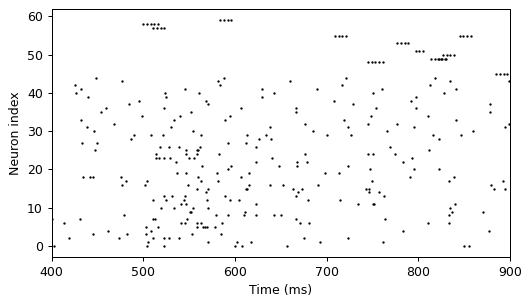

In [4]:
sp_matrix = np.zeros((t_grid.size, len(spikes)), dtype=bool)
sp_matrix[np.minimum((times / dt).astype(int), t_grid.size - 1), ids] = True

fig, ax = plt.subplots(figsize=(6, 3.5))
braintools.visualize.raster_plot(t_grid * 1000, sp_matrix, ax=ax, markersize=3, xlim=(400, 900))
plt.tight_layout(); plt.show()

## 3. Population Rate and PSTH

To compare activity across trials, pool spikes over trials. `spike_histogram` histograms spike times; with `bin_size` and `time_range` the bins are aligned to the trial. Its y-axis is a spike **count** (or, with `density=True`, a probability density over time), not a rate. For a rate in Hz, divide the counts by the number of trials, neurons and the bin width, or bin the spikes yourself and use `population_activity`, which averages a `(time, neuron)` matrix over neurons and can smooth it with a box filter of `window_size` samples:

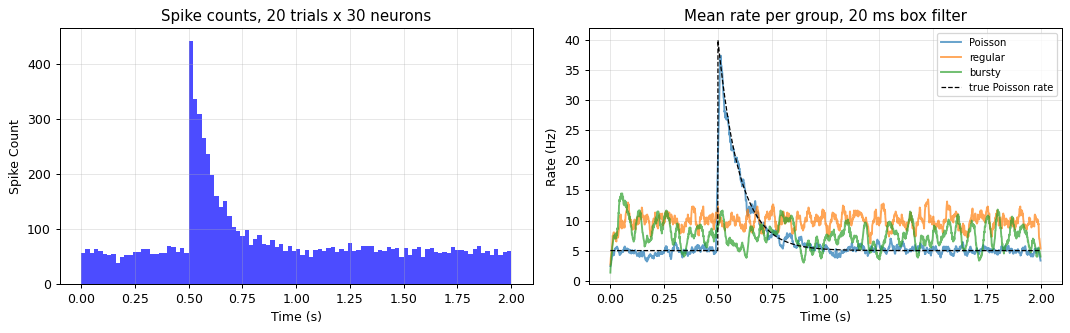

Poisson group: measured rate 0.50-0.52 s 36.9 Hz, true mean over that window 36.9 Hz


In [5]:
bin_size = 0.02
poisson_times = np.concatenate([np.concatenate(tr[:30]) for tr in trials])   # Poisson group, all trials

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
braintools.visualize.spike_histogram(poisson_times, bin_size=bin_size, time_range=(0, T), ax=ax[0],
                                     xlabel="Time (s)", title="Spike counts, 20 trials x 30 neurons")

# rate matrix in Hz: spike counts per 1 ms bin, averaged over trials, divided by dt
counts = np.zeros((t_grid.size, 60))
for tr in trials:
    for i, s in enumerate(tr):
        np.add.at(counts[:, i], np.minimum((s / dt).astype(int), t_grid.size - 1), 1)
rate = counts / n_trials / dt
for group, (lo, hi), color in [("Poisson", (0, 30), "C0"), ("regular", (30, 45), "C1"), ("bursty", (45, 60), "C2")]:
    braintools.visualize.population_activity(rate, time=t_grid, neuron_ids=np.arange(lo, hi), window_size=20,
                                             fill=False, color=color, ax=ax[1], label=group)
ax[1].plot(t_grid, poisson_rate(t_grid), "k--", lw=1, label="true Poisson rate")
ax[1].set_xlabel("Time (s)"); ax[1].set_ylabel("Rate (Hz)"); ax[1].set_title("Mean rate per group, 20 ms box filter")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

peak = rate[:, :30].mean(1)[(t_grid >= 0.5) & (t_grid < 0.52)].mean()
print(f"Poisson group: measured rate 0.50-0.52 s {peak:.1f} Hz, true mean over that window "
      f"{poisson_rate(t_grid[(t_grid >= 0.5) & (t_grid < 0.52)]).mean():.1f} Hz")

The smoothed rate follows the true rate; the box filter blurs the sharp onset over 20 ms, and with `mode='same'` convolution it also pulls the rate towards zero within half a window of either end of the recording. `population_activity` also offers `method='sum'`, `'std'`, `'var'` and `'median'` across neurons.

## 4. Inter-Spike Intervals

`isi_distribution` computes the intervals **within** each spike train and annotates the plot with the mean ISI and the coefficient of variation CV = std / mean: about 1 for a Poisson process, below 1 for regular firing, above 1 for bursty firing. A list of trains is split per neuron; a flat array is treated as one train (pass a list to avoid intervals between different neurons).

Poisson : mean ISI  128.9 ms, CV 1.09
regular : mean ISI   99.5 ms, CV 0.36
bursty  : mean ISI   73.6 ms, CV 2.74


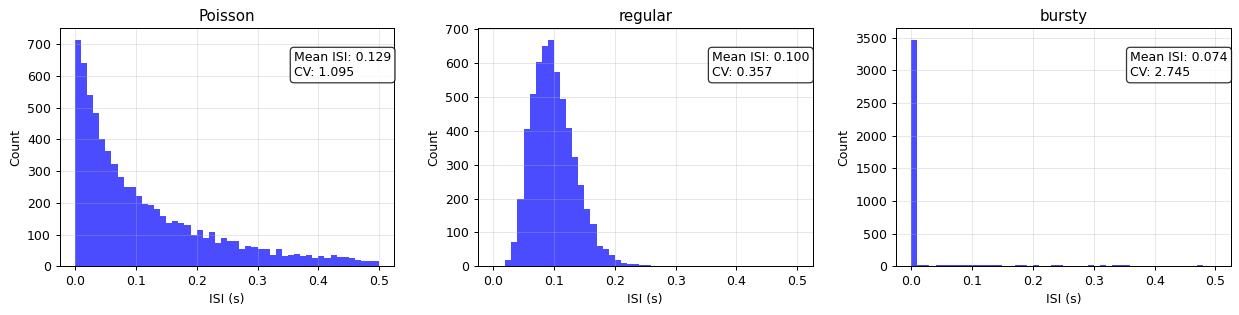

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
pooled = {name: [s for tr in trials for s in tr[lo:hi]] for name, lo, hi in [("Poisson", 0, 30), ("regular", 30, 45), ("bursty", 45, 60)]}
for a, (name, trains) in zip(ax, pooled.items()):
    braintools.visualize.isi_distribution(trains, bins=np.linspace(0, 0.5, 51), ax=a, title=name, xlabel="ISI (s)")
    isis = np.concatenate([np.diff(s) for s in trains])
    print(f"{name:8s}: mean ISI {isis.mean() * 1000:6.1f} ms, CV {isis.std() / isis.mean():.2f}")
plt.tight_layout(); plt.show()

The CVs follow the expected ordering: the gamma process of order 8 has a CV close to $1/\sqrt{8} \approx 0.35$, the Poisson neurons close to 1 (slightly above, because their rate varies over time), and the bursty neurons well above 1, with a sharp peak at the 4 ms intra-burst interval. With `log_scale=True` the **count axis** becomes logarithmic, which helps to see the tail of long intervals.

## 5. Spatial Firing-Rate Maps

`firing_rate_map` accepts either a ready 2-D map or per-sample rates with positions. In the second case it bins the positions on a `grid_size = (nx, ny)` grid and shows the mean rate of the samples in each bin. Bins that were never visited have no data and stay blank, so they cannot be mistaken for a silent region; the axes are in position units.

A simulated place cell: an animal performs a random walk in a 1 m × 1 m box but avoids its upper-left corner, and the cell fires around (0.6, 0.4) m:

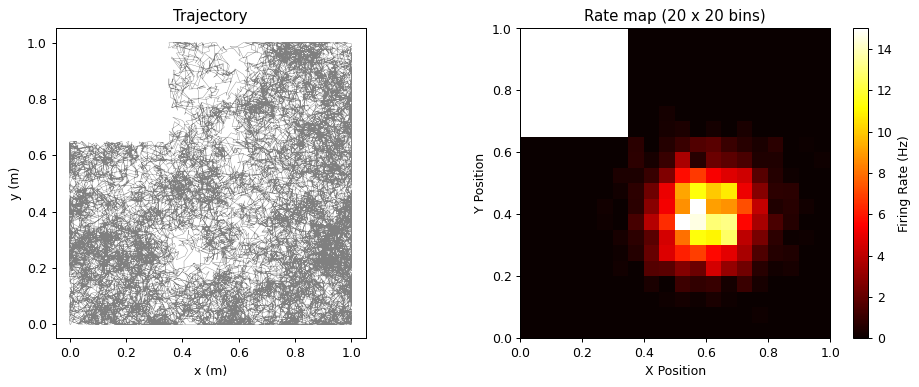

In [7]:
n = 20000
pos = np.zeros((n, 2)); pos[0] = (0.5, 0.5)
for k in range(1, n):
    step = pos[k - 1] + rng.normal(0, 0.02, 2)
    if step[0] < 0.35 and step[1] > 0.65:      # never enters the upper-left corner
        step = pos[k - 1]
    pos[k] = np.clip(step, 0, 1)
true_rate = 15 * np.exp(-np.sum((pos - [0.6, 0.4]) ** 2, axis=1) / (2 * 0.1 ** 2))
rates = rng.poisson(true_rate * 0.1) / 0.1                    # spike counts in 100 ms windows, as Hz

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].plot(pos[:, 0], pos[:, 1], lw=0.3, color="gray")
ax[0].set_aspect("equal"); ax[0].set_title("Trajectory"); ax[0].set_xlabel("x (m)"); ax[0].set_ylabel("y (m)")
braintools.visualize.firing_rate_map(rates, positions=pos, grid_size=(20, 20), interpolation="nearest",
                                     ax=ax[1], title="Rate map (20 x 20 bins)")
plt.tight_layout(); plt.show()

The field appears around (0.6, 0.4) m; the corner the animal never entered is blank rather than "0 Hz". Interpolation other than `'nearest'` smooths between bins for display only.

## 6. Traces

`line_plot(ts, val_matrix, plot_ids=...)` plots selected columns of a `(time, neuron)` matrix, for example membrane potentials from a simulation. Here, three leaky integrate-and-fire neurons (threshold 1, reset 0, $	au$ = 10 ms) with constant inputs $I$ = 0.9, 1.1 and 1.4 plus noise (Euler integration, 0.1 ms steps). With $I = 0.9$ the steady-state potential is below threshold, so that neuron fires only when noise pushes it across:

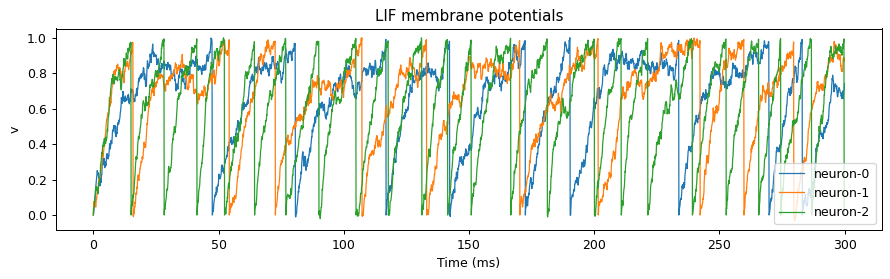

In [8]:
dt_ms, n_steps = 0.1, 3000
I = np.array([0.9, 1.1, 1.4])
v = np.zeros((n_steps, 3))
for k in range(1, n_steps):
    v[k] = v[k - 1] + dt_ms / 10.0 * (-v[k - 1] + I) + 0.05 * np.sqrt(dt_ms) * rng.normal(size=3)
    v[k][v[k] >= 1.0] = 0.0                                   # threshold 1, reset 0
fig, ax = plt.subplots(figsize=(10, 3.2))
braintools.visualize.line_plot(np.arange(n_steps) * dt_ms, v, plot_ids=[0, 1, 2], ax=ax,
                               legend="neuron", ylabel="v", title="LIF membrane potentials")
plt.tight_layout(); plt.show()

## Summary

- `spike_raster` takes spike times as a list of trains or as times plus `neuron_ids`; `raster_plot` takes a boolean `(time, neuron)` matrix from a simulation.
- `spike_histogram` shows spike **counts** (or a density over time); for rates in Hz divide by trials, neurons and bin width, or average a binned rate matrix with `population_activity`.
- `isi_distribution` computes intervals within each train and reports mean ISI and CV.
- `firing_rate_map` bins positions, averages the rates per bin, leaves unvisited bins blank and labels the axes in position units.
- Every function accepts an `ax`, so views combine into multi-panel figures.